In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import plotly.express as px

## Timely and Effective Care

### Facility Level

In [11]:
timely_care_hospital = pd.read_csv("../Data_standard/facility_hospital_timely_effective_care.csv")
timely_care_state = pd.read_csv("../Data_standard/state_hospital_timely_effective_care.csv")

/var/folders/0b/t60b2bh11pq2yknx9_cvds240000gn/T/ipykernel_10310/2154101574.py:1: DtypeWarning: Columns (3) have mixed types. Specify dtype option on import or set low_memory=False.
  timely_care_hospital = pd.read_csv("../Data_standard/facility_hospital_timely_effective_care.csv")


In [12]:
timely_care_hospital.head()

,geography_level,facility_type,source_file,facility_id,npi,shared_facility_id,facility_name,address,city,state,...,score,score_text,score_status,vs_national,cases,ci_lower,ci_upper,footnote_code,period_start,period_end
0,facility,hospital,Timely_and_Effective_Care-Hospital.csv,010001,NaN,False,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,...,NaN,very high,reported,Not Available,NaN,NaN,NaN,NaN,2024-01-01,2024-12-31
1,facility,hospital,Timely_and_Effective_Care-Hospital.csv,010001,NaN,False,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,...,NaN,NaN,Not Available,Not Available,NaN,NaN,NaN,5,2024-01-01,2024-12-31
2,facility,hospital,Timely_and_Effective_Care-Hospital.csv,010001,NaN,False,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,...,NaN,NaN,Not Available,Not Available,NaN,NaN,NaN,5,2024-01-01,2024-12-31
3,facility,hospital,Timely_and_Effective_Care-Hospital.csv,010001,NaN,False,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,...,NaN,NaN,Not Available,Not Available,NaN,NaN,NaN,5,2024-01-01,2024-12-31
4,facility,hospital,Timely_and_Effective_Care-Hospital.csv,010001,NaN,False,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,...,NaN,NaN,Not Available,Not Available,NaN,NaN,NaN,5,2024-01-01,2024-12-31


In [25]:
timely_care_hospital = timely_care_hospital[(timely_care_hospital["score_status"] != "Not Available") & (timely_care_hospital["score_text"].isna())]

,geography_level,facility_type,source_file,facility_id,npi,shared_facility_id,facility_name,address,city,state,...,score,score_text,score_status,vs_national,cases,ci_lower,ci_upper,footnote_code,period_start,period_end
9,facility,hospital,Timely_and_Effective_Care-Hospital.csv,010001,NaN,False,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,...,93.0,NaN,reported,Not Available,4625.0,NaN,NaN,NaN,2024-10-01,2025-03-31
10,facility,hospital,Timely_and_Effective_Care-Hospital.csv,010001,NaN,False,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,...,214.0,NaN,reported,Not Available,405.0,NaN,NaN,NaN,2024-10-01,2025-09-30
11,facility,hospital,Timely_and_Effective_Care-Hospital.csv,010001,NaN,False,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,...,212.0,NaN,reported,Not Available,396.0,NaN,NaN,NaN,2024-10-01,2025-09-30
14,facility,hospital,Timely_and_Effective_Care-Hospital.csv,010001,NaN,False,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,...,3.0,NaN,reported,Not Available,62163.0,NaN,NaN,NaN,2024-01-01,2024-12-31
15,facility,hospital,Timely_and_Effective_Care-Hospital.csv,010001,NaN,False,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,...,82.0,NaN,reported,Not Available,11.0,NaN,NaN,NaN,2024-10-01,2025-09-30


In [15]:
print(timely_care_hospital['state'].nunique())

# only include the 50 states and DC
states = [
    'AK', 'AL', 'AR', 'AZ', 'CA', 'CO', 'CT', 'DC', 'DE', 'FL',
    'GA', 'HI', 'IA', 'ID', 'IL', 'IN', 'KS', 'KY', 'LA', 'MA',
    'MD', 'ME', 'MI', 'MN', 'MO', 'MS', 'MT', 'NC', 'ND', 'NE',
    'NH', 'NJ', 'NM', 'NV', 'NY', 'OH', 'OK', 'OR', 'PA', 'RI',
    'SC', 'SD', 'TN', 'TX', 'UT', 'VA', 'VT', 'WA', 'WI', 'WV',
    'WY'
]

timely_care_hospital = timely_care_hospital[timely_care_hospital['state'].isin(states)].copy()
print(timely_care_hospital['state'].nunique())

54
51


In [17]:
measures = timely_care_hospital["measure_short_name"].unique()
timely_care_hospital['score'] = pd.to_numeric(timely_care_hospital['score'], errors='coerce')

# Create one row per facility and one column per measure
scores = timely_care_hospital.pivot_table(
    index='facility_id',
    columns='measure_short_name',
    values='score',
    aggfunc='mean'
)

# Include all measures, even if some are absent
scores = scores.reindex(columns=measures)

# Count missing measures per facility
missing_count = scores.isna().sum(axis=1)

# Total number of facilities
total_facilities = len(scores)

,Missing Facilities,Total Facilities,Percentage Missing
measure_short_name,,,
cataract_visual_function_improved_pct,4382,4396,99.68
stroke_anticoagulation_afib,4102,4396,93.31
stemi_measure_op40,4004,4396,91.08
harm_opioid_adverse_events,3760,4396,85.53
harm_severe_hyperglycemia,3468,4396,78.89
stroke_antithrombotic_by_day2,3108,4396,70.70
icu_vte_prophylaxis,3017,4396,68.63
harm_severe_hypoglycemia,2990,4396,68.02
ed_head_ct_results_timely_pct,2907,4396,66.13


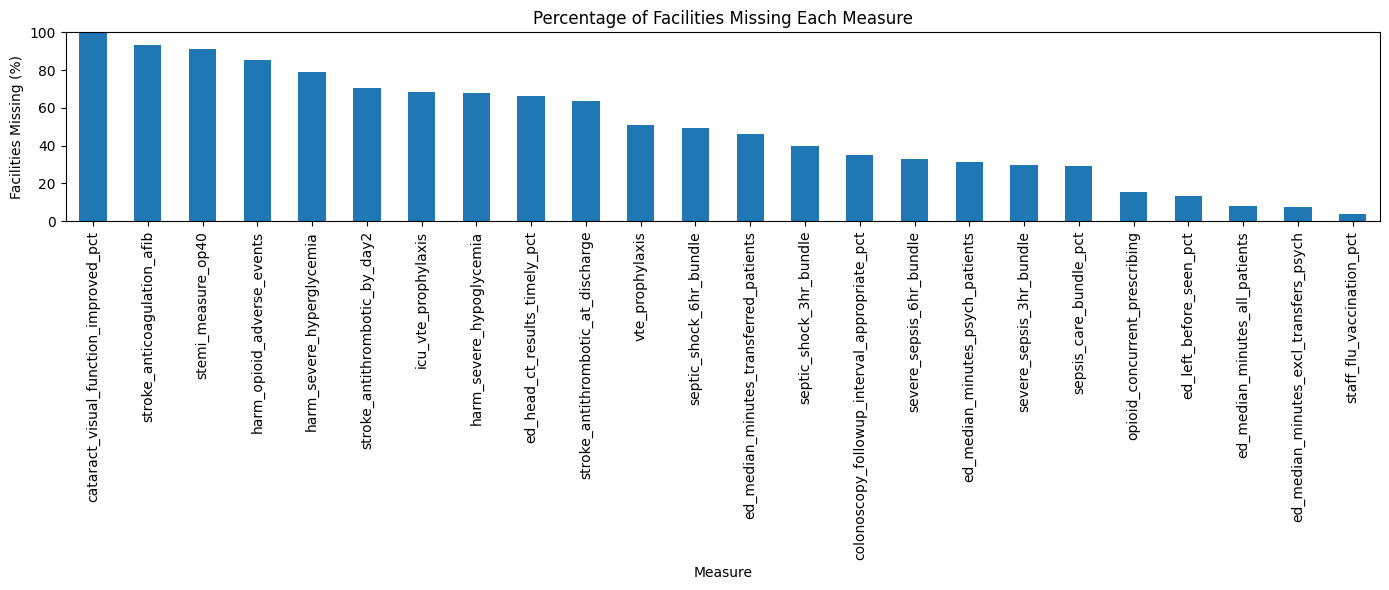

In [18]:
# Create summary table
missing_by_measure = pd.DataFrame({
    'Missing Facilities': scores.isna().sum(),
    'Total Facilities': len(scores),
    'Percentage Missing': scores.isna().mean() * 100
}).sort_values('Percentage Missing', ascending=False)

# Bar chart
ax = missing_by_measure['Percentage Missing'].plot(
    kind='bar',
    figsize=(14, 6)
)

ax.set_title('Percentage of Facilities Missing Each Measure')
ax.set_xlabel('Measure')
ax.set_ylabel('Facilities Missing (%)')
ax.tick_params(axis='x', rotation=90)
ax.set_ylim(0, 100)

plt.tight_layout()
plt.show()

,Number of Measures Missing,Number of Facilities,Percentage of Facilities
0,2,6,0.14
1,3,7,0.16
2,4,12,0.27
3,5,13,0.30
4,6,81,1.84
5,7,477,10.85
6,8,744,16.92
7,9,687,15.63
8,10,370,8.42
9,11,205,4.66


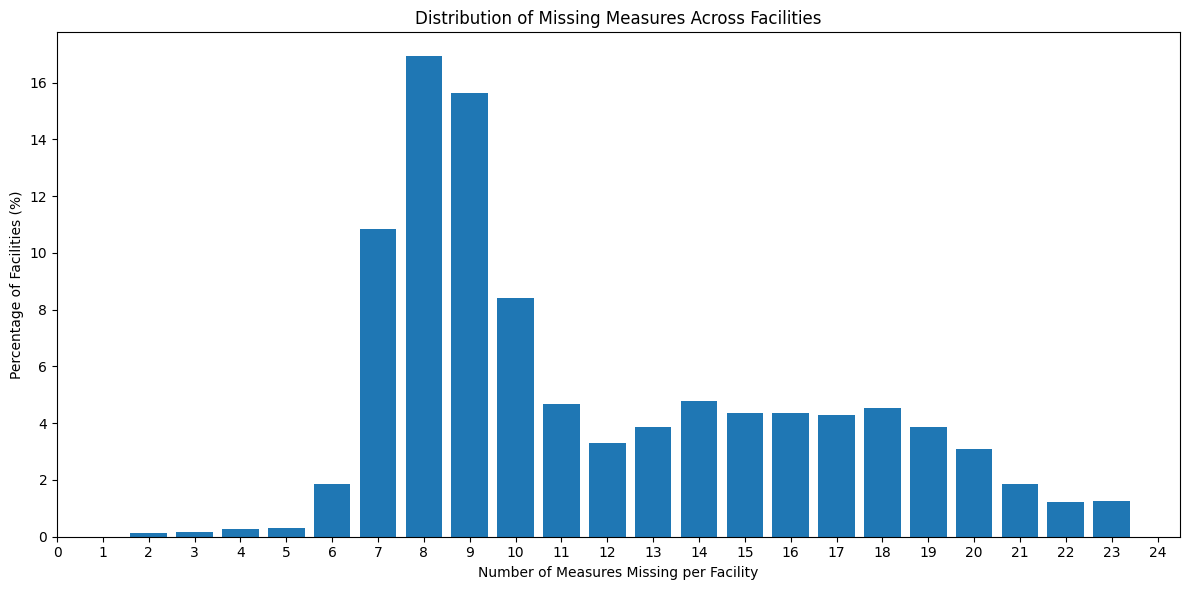

In [19]:
# Count facilities missing each possible number of measures
missing_distribution = (
    missing_count
    .value_counts()
    .reindex(range(len(measures) + 1), fill_value=0)
    .sort_index()
)

# Create summary table
distribution_table = pd.DataFrame({
    'Number of Measures Missing': missing_distribution.index,
    'Number of Facilities': missing_distribution.values,
    'Percentage of Facilities':
        missing_distribution.values / total_facilities * 100
})

# Display only counts that occur in the data
distribution_table = distribution_table[
    distribution_table['Number of Facilities'] > 0
].reset_index(drop=True)

# Bar chart
plt.figure(figsize=(12, 6))

plt.bar(
    distribution_table['Number of Measures Missing'],
    distribution_table['Percentage of Facilities']
)

plt.title('Distribution of Missing Measures Across Facilities')
plt.xlabel('Number of Measures Missing per Facility')
plt.ylabel('Percentage of Facilities (%)')
plt.xticks(range(len(measures) + 1))
plt.tight_layout()
plt.show()

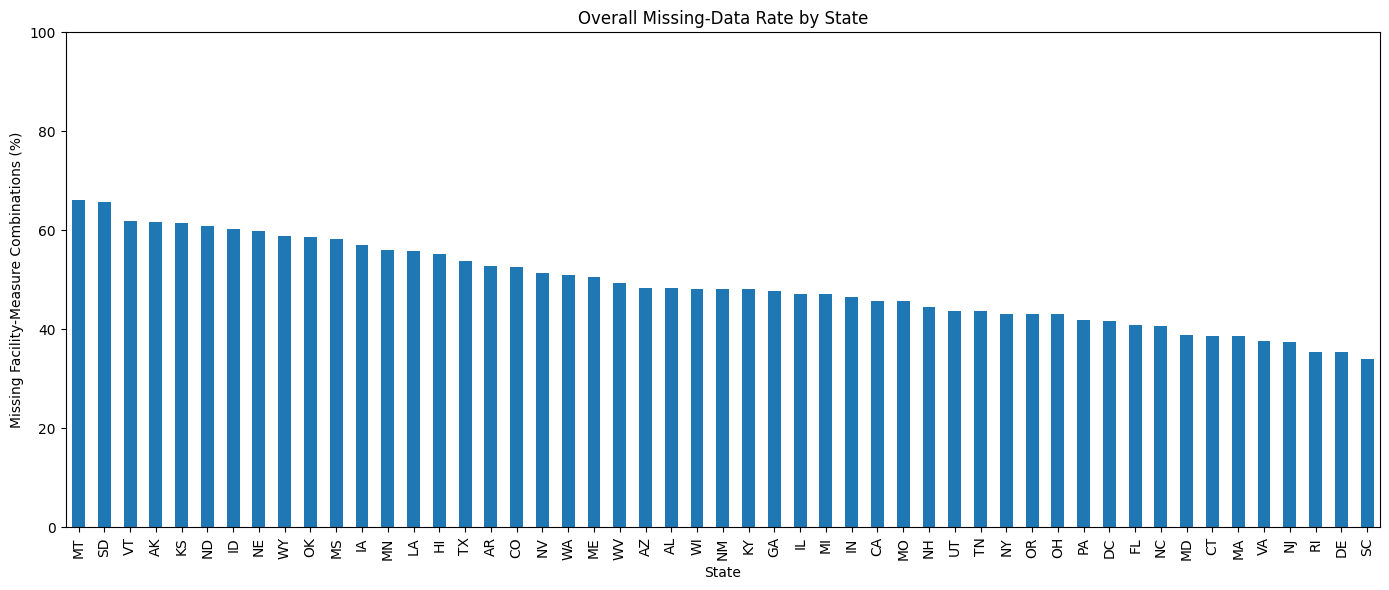

,Missing Data (%),Facilities
state,,
AK,61.78,23
AL,48.28,80
AR,52.84,69
AZ,48.34,78
CA,45.77,315
CO,52.63,84
CT,38.62,26
DC,41.67,6
DE,35.42,6


In [21]:
# Create one row per facility and one column per measure
scores = timely_care_hospital.pivot_table(
    index=['state', 'facility_id'],
    columns='measure_short_name',
    values='score',
    aggfunc='mean'
)

# Include all 24 measures
scores = scores.reindex(columns=measures)

# Calculate missing data for each facility
missing = scores.isna()

# Average percentage of missing scores across all facilities and measures
state_missing_pct = missing.groupby(level='state').mean().mean(axis=1) * 100

# Sort from highest to lowest
state_missing_pct = state_missing_pct.sort_values(ascending=False)

plt.figure(figsize=(14, 6))

state_missing_pct.plot(kind='bar')

plt.title('Overall Missing-Data Rate by State')
plt.xlabel('State')
plt.ylabel('Missing Facility-Measure Combinations (%)')
plt.xticks(rotation=90)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

# Summary table
state_missing_summary = pd.DataFrame({
    'Missing Data (%)': state_missing_pct,
    'Facilities': scores.groupby(level='state').size()
})


### State Level

In [26]:
timely_care_state.head()

,geography_level,facility_type,source_file,state,measure_group,condition,measure_id,measure_short_name,measure_name,better_direction,ed_volume_tier,statistic,value,value_status,footnote_code,period_start,period_end
0,state,hospital,Timely_and_Effective_Care-State.csv,AK,Timely and Effective Care,Healthcare Personnel Vaccination,IMM_3,staff_flu_vaccination_pct,Healthcare workers given influenza vaccination...,higher,NaN,score,74.0,reported,NaN,2024-10-01,2025-03-31
1,state,hospital,Timely_and_Effective_Care-State.csv,AK,Timely and Effective Care,Emergency Department,OP_18a,ed_median_minutes_all_patients,Average (median) time all patients spent in th...,lower,NaN,score,143.0,reported,NaN,2024-10-01,2025-09-30
2,state,hospital,Timely_and_Effective_Care-State.csv,AK,Timely and Effective Care,Emergency Department,OP_18a,ed_median_minutes_all_patients,Average (median) time all patients spent in th...,lower,high,score,156.0,reported,NaN,2024-10-01,2025-09-30
3,state,hospital,Timely_and_Effective_Care-State.csv,AK,Timely and Effective Care,Emergency Department,OP_18a,ed_median_minutes_all_patients,Average (median) time all patients spent in th...,lower,low,score,136.0,reported,NaN,2024-10-01,2025-09-30
4,state,hospital,Timely_and_Effective_Care-State.csv,AK,Timely and Effective Care,Emergency Department,OP_18a,ed_median_minutes_all_patients,Average (median) time all patients spent in th...,lower,medium,score,152.0,reported,NaN,2024-10-01,2025-09-30


In [24]:
print(timely_care_state['state'].nunique())

# only include the 50 states and DC
states = [
    'AK', 'AL', 'AR', 'AZ', 'CA', 'CO', 'CT', 'DC', 'DE', 'FL',
    'GA', 'HI', 'IA', 'ID', 'IL', 'IN', 'KS', 'KY', 'LA', 'MA',
    'MD', 'ME', 'MI', 'MN', 'MO', 'MS', 'MT', 'NC', 'ND', 'NE',
    'NH', 'NJ', 'NM', 'NV', 'NY', 'OH', 'OK', 'OR', 'PA', 'RI',
    'SC', 'SD', 'TN', 'TX', 'UT', 'VA', 'VT', 'WA', 'WI', 'WV',
    'WY'
]

timely_care_state = timely_care_state[timely_care_state['state'].isin(states)].copy()
print(timely_care_state['state'].nunique())

56
51


In [32]:
print(timely_care_state['value_status'].unique())
print(timely_care_state[timely_care_state['value_status']=='Not Available']['state'].unique())

['reported' 'Not Available']
['AK' 'AR' 'AZ' 'CO' 'CT' 'DC' 'DE' 'FL' 'HI' 'IA' 'ID' 'KY' 'LA' 'MA'
 'ME' 'MI' 'MN' 'MS' 'MT' 'NC' 'ND' 'NE' 'NH' 'NJ' 'NM' 'NV' 'OH' 'PA'
 'RI' 'SC' 'SD' 'TN' 'UT' 'VA' 'VT' 'WA' 'WI' 'WY']


In [34]:
timely_care_state = timely_care_state[timely_care_state["value_status"] != "Not Available"]
timely_care_state.head()

,geography_level,facility_type,source_file,state,measure_group,condition,measure_id,measure_short_name,measure_name,better_direction,ed_volume_tier,statistic,value,value_status,footnote_code,period_start,period_end
0,state,hospital,Timely_and_Effective_Care-State.csv,AK,Timely and Effective Care,Healthcare Personnel Vaccination,IMM_3,staff_flu_vaccination_pct,Healthcare workers given influenza vaccination...,higher,NaN,score,74.0,reported,NaN,2024-10-01,2025-03-31
1,state,hospital,Timely_and_Effective_Care-State.csv,AK,Timely and Effective Care,Emergency Department,OP_18a,ed_median_minutes_all_patients,Average (median) time all patients spent in th...,lower,NaN,score,143.0,reported,NaN,2024-10-01,2025-09-30
2,state,hospital,Timely_and_Effective_Care-State.csv,AK,Timely and Effective Care,Emergency Department,OP_18a,ed_median_minutes_all_patients,Average (median) time all patients spent in th...,lower,high,score,156.0,reported,NaN,2024-10-01,2025-09-30
3,state,hospital,Timely_and_Effective_Care-State.csv,AK,Timely and Effective Care,Emergency Department,OP_18a,ed_median_minutes_all_patients,Average (median) time all patients spent in th...,lower,low,score,136.0,reported,NaN,2024-10-01,2025-09-30
4,state,hospital,Timely_and_Effective_Care-State.csv,AK,Timely and Effective Care,Emergency Department,OP_18a,ed_median_minutes_all_patients,Average (median) time all patients spent in th...,lower,medium,score,152.0,reported,NaN,2024-10-01,2025-09-30


In [44]:
# Convert scores to numeric
timely_care_state['value'] = pd.to_numeric(timely_care_state['value'], errors='coerce')

measures = timely_care_state["measure_short_name"].unique()

# Create one row per state and one column per measure
state_scores = timely_care_state.pivot_table(
    index='state',
    columns='measure_short_name',
    values='value',
    aggfunc='mean'
).reindex(columns=measures)

# Count missing measures per state
state_missing_count = state_scores.isna().sum(axis=1)

# Create summary table
state_missing_summary = pd.DataFrame({
    'Measures Missing': state_missing_count,
    'Measures Available': state_scores.notna().sum(axis=1),
    'Percentage Missing': state_scores.isna().mean(axis=1) * 100
}).sort_values('Measures Missing', ascending=False)

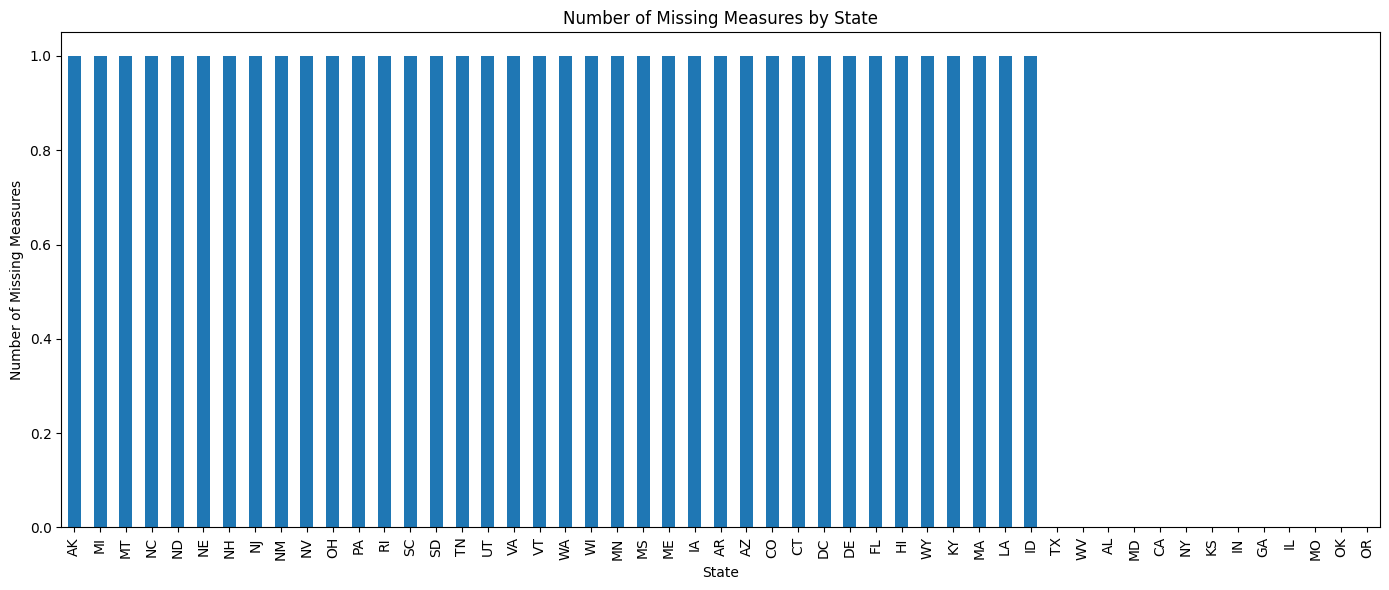

In [45]:
state_missing_count.sort_values(ascending=False).plot(
    kind='bar',
    figsize=(14, 6)
)

plt.title('Number of Missing Measures by State')
plt.xlabel('State')
plt.ylabel('Number of Missing Measures')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

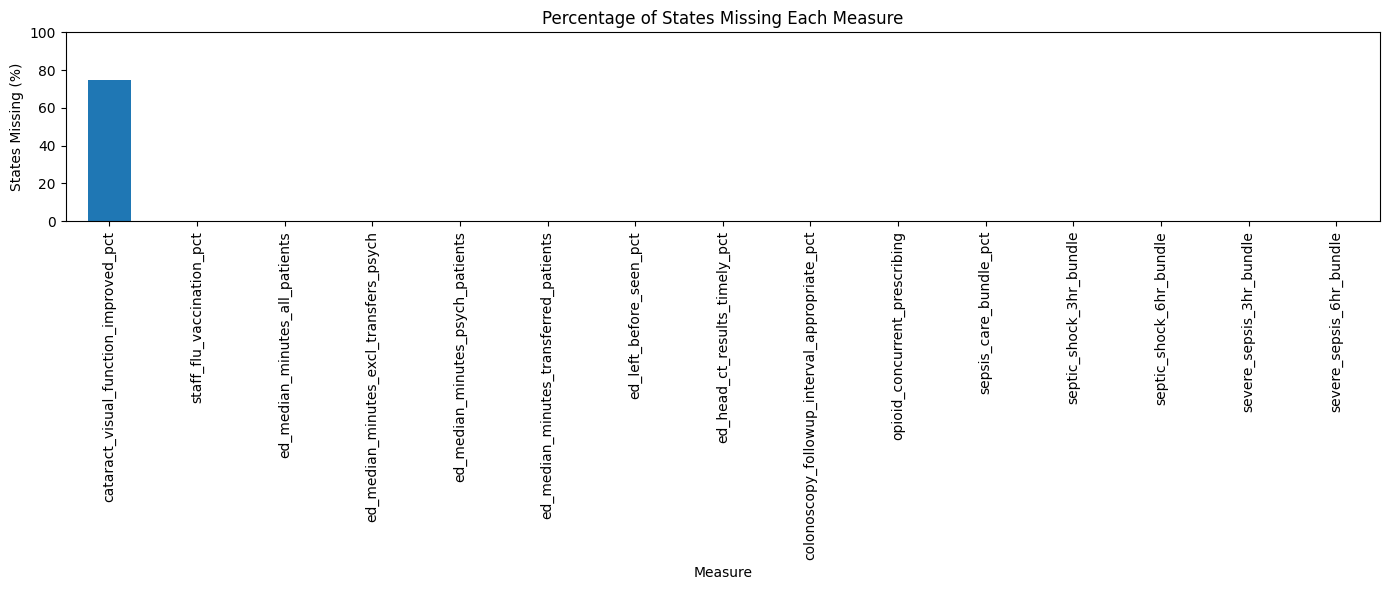

In [46]:
# Identify missing measures for each state
missing_measures_by_state = pd.DataFrame({
    'Missing Measures': state_scores.isna().apply(
        lambda row: row.index[row].tolist(),
        axis=1
    )
})

missing_measures_by_state['Number Missing'] = (
    state_scores.isna().sum(axis=1)
)

# Count states missing each measure
missing_by_measure_state = pd.DataFrame({
    'States Missing': state_scores.isna().sum(),
    'Percentage of States Missing':
        state_scores.isna().mean() * 100
}).sort_values('States Missing', ascending=False)

missing_by_measure_state['Percentage of States Missing'].plot(
    kind='bar',
    figsize=(14, 6)
)

plt.title('Percentage of States Missing Each Measure')
plt.xlabel('Measure')
plt.ylabel('States Missing (%)')
plt.xticks(rotation=90)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

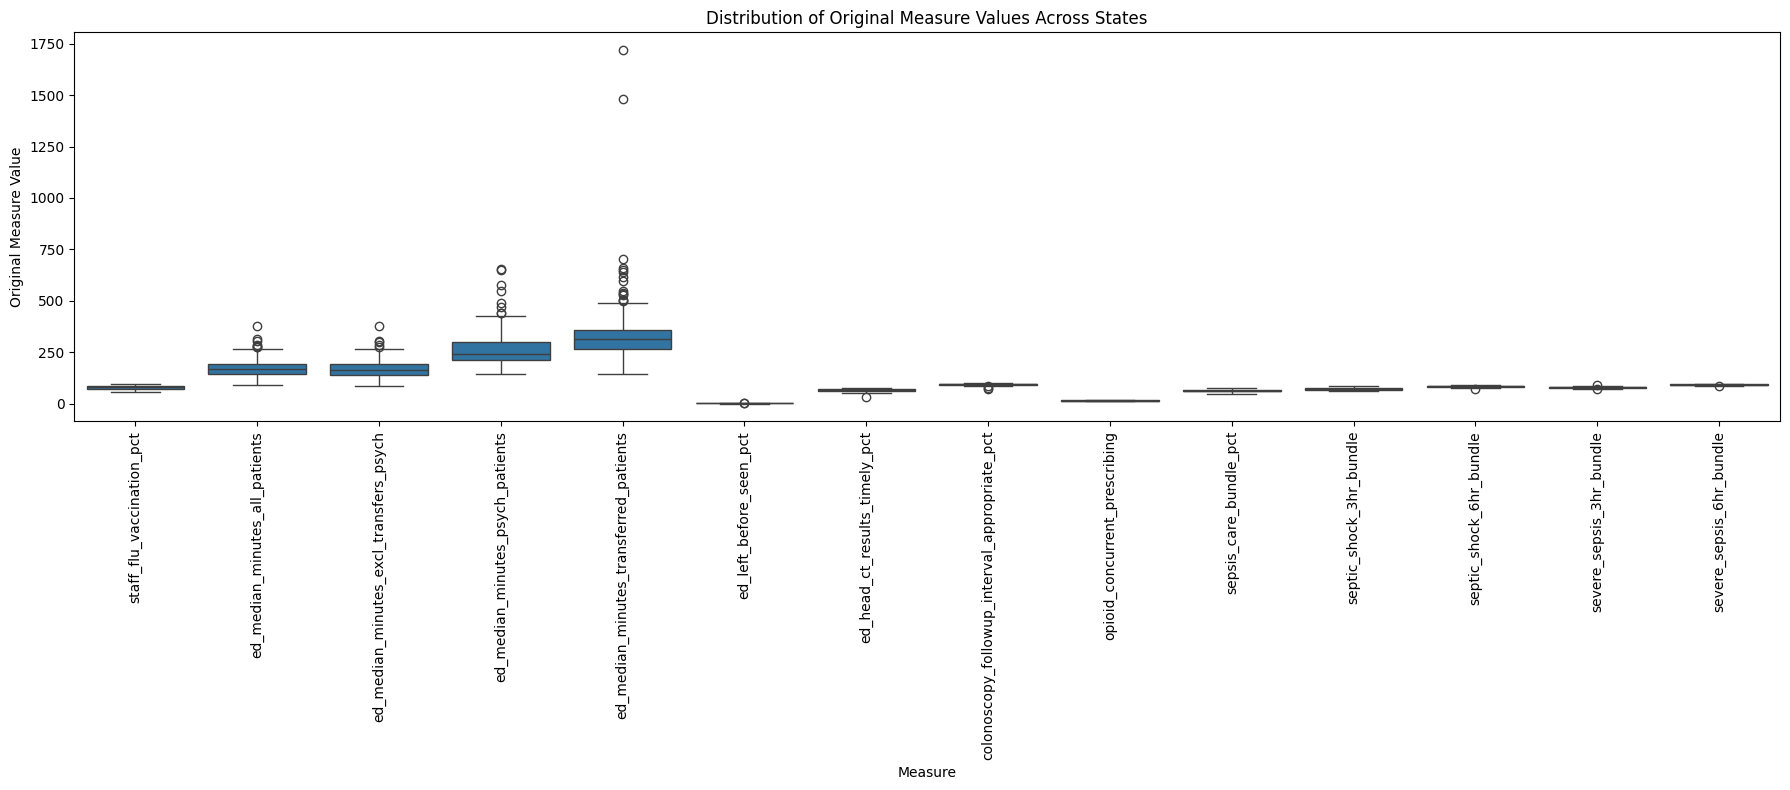

In [51]:
# Exclude cataract measure
data = timely_care_state[
    timely_care_state['measure_short_name']
    != 'cataract_visual_function_improved_pct'
].copy()

# Ensure scores are numeric
data['value'] = pd.to_numeric(data['value'], errors='coerce')

plt.figure(figsize=(18, 8))

sns.boxplot(
    data=data,
    x='measure_short_name',
    y='value'
)

plt.title('Distribution of Original Measure Values Across States')
plt.xlabel('Measure')
plt.ylabel('Original Measure Value')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [52]:
# Standardize each measure to a 0–100 scale
def standardize_measure(group):
    min_val = group['value'].min()
    max_val = group['value'].max()

    if pd.isna(min_val) or pd.isna(max_val) or min_val == max_val:
        group['standardized_score'] = 50
    else:
        if group['better_direction'].iloc[0] == 'higher':
            group['standardized_score'] = (
                (group['value'] - min_val) / (max_val - min_val) * 100
            )
        else:
            group['standardized_score'] = (
                (max_val - group['value']) / (max_val - min_val) * 100
            )

    return group

data = data.groupby(
    'measure_short_name', group_keys=False
).apply(standardize_measure)

# Calculate average standardized score for each state
state_scores = (
    data.groupby('state')['standardized_score']
    .mean()
    .sort_values(ascending=False)
)

state_ranking = state_scores.reset_index()
state_ranking.columns = ['State', 'Average Score']

/var/folders/0b/t60b2bh11pq2yknx9_cvds240000gn/T/ipykernel_10310/2227111959.py:22: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  ).apply(standardize_measure)


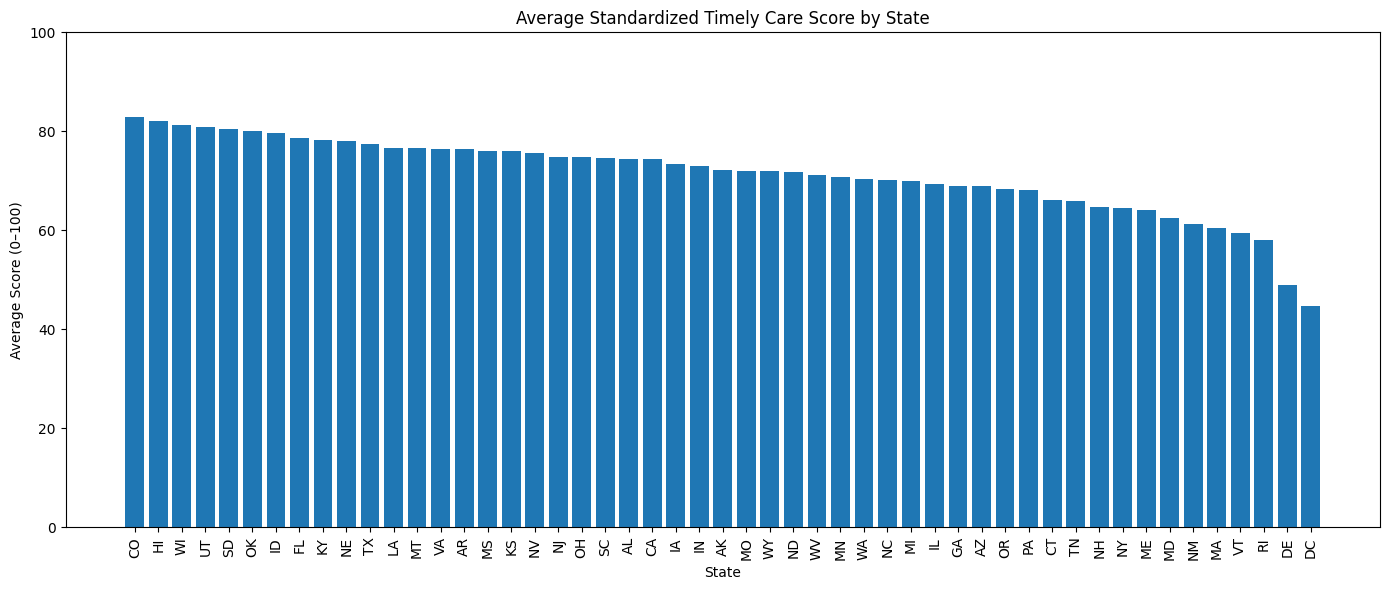

In [53]:
plt.figure(figsize=(14, 6))

plt.bar(state_ranking['State'], state_ranking['Average Score'])

plt.title('Average Standardized Timely Care Score by State')
plt.xlabel('State')
plt.ylabel('Average Score (0–100)')
plt.xticks(rotation=90)
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

/var/folders/0b/t60b2bh11pq2yknx9_cvds240000gn/T/ipykernel_10310/1574753100.py:27: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  ).apply(standardize_measure)
/var/folders/0b/t60b2bh11pq2yknx9_cvds240000gn/T/ipykernel_10310/1574753100.py:40: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  ).apply(standardize_measure)


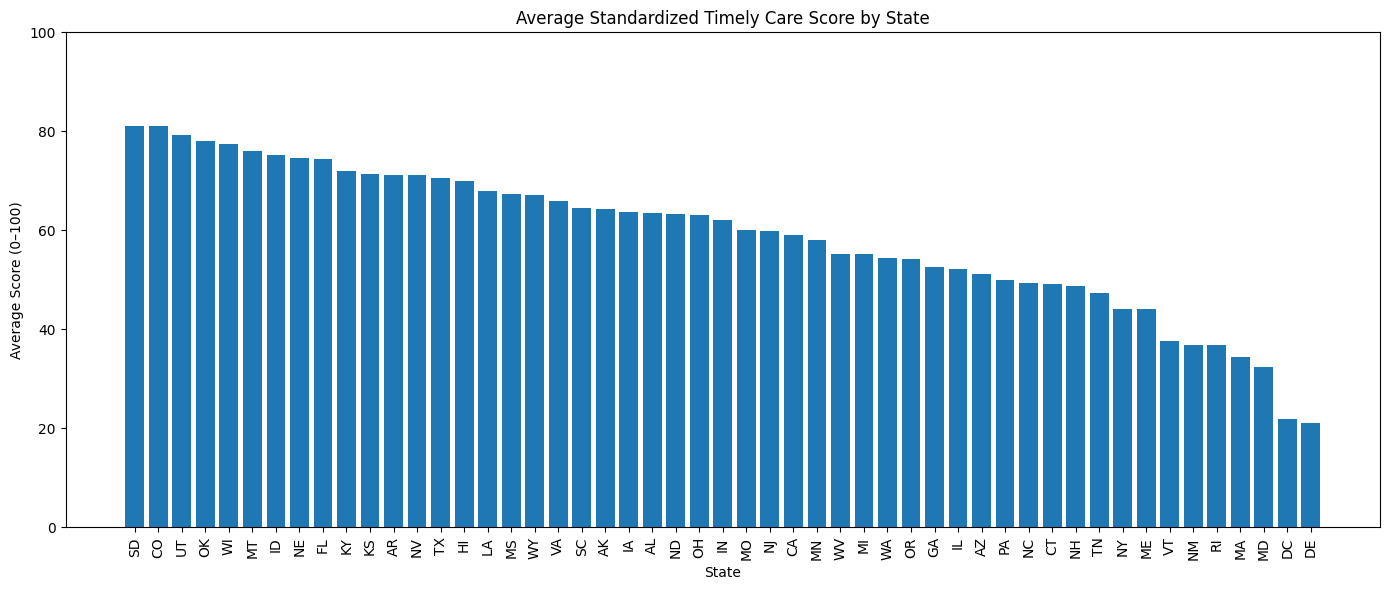

In [54]:
# 5th–95th percentile scaling to standardize

def standardize_measure(group):
    lower = group['value'].quantile(0.05)
    upper = group['value'].quantile(0.95)

    if pd.isna(lower) or pd.isna(upper) or lower == upper:
        group['standardized_score'] = 50
        return group

    # Cap values at the 5th and 95th percentiles
    capped = group['value'].clip(lower=lower, upper=upper)

    if group['better_direction'].iloc[0] == 'higher':
        group['standardized_score'] = (
            (capped - lower) / (upper - lower) * 100
        )
    else:
        group['standardized_score'] = (
            (upper - capped) / (upper - lower) * 100
        )

    return group

data = data.groupby(
    'measure_short_name', group_keys=False
).apply(standardize_measure)

state_ranking = (
    data.groupby('state')['standardized_score']
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

state_ranking.columns = ['State', 'Average Score']

data = data.groupby(
    'measure_short_name', group_keys=False
).apply(standardize_measure)

# Calculate average standardized score for each state
state_scores = (
    data.groupby('state')['standardized_score']
    .mean()
    .sort_values(ascending=False)
)

state_ranking = state_scores.reset_index()
state_ranking.columns = ['State', 'Average Score']

plt.figure(figsize=(14, 6))

plt.bar(state_ranking['State'], state_ranking['Average Score'])

plt.title('Average Standardized Timely Care Score by State')
plt.xlabel('State')
plt.ylabel('Average Score (0–100)')
plt.xticks(rotation=90)
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

## Death and Complications

### Facility Level

In [56]:
death_comp_hospital = pd.read_csv("../Data_standard/facility_hospital_complications_deaths.csv")
death_comp_state = pd.read_csv("../Data_standard/state_hospital_complications_deaths.csv")

In [104]:
death_comp_hospital.head()

,geography_level,facility_type,source_file,facility_id,npi,shared_facility_id,facility_name,address,city,state,...,score,score_text,score_status,vs_national,cases,ci_lower,ci_upper,footnote_code,period_start,period_end
0,facility,hospital,Complications_and_Deaths-Hospital.csv,010001,NaN,False,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,...,3.8,NaN,reported,No Different,33.0,2.4,6.0,NaN,2023-04-01,2025-03-31
1,facility,hospital,Complications_and_Deaths-Hospital.csv,010001,NaN,False,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,...,4.4,NaN,reported,No Different,4972.0,3.9,5.0,NaN,2024-07-01,2025-06-30
2,facility,hospital,Complications_and_Deaths-Hospital.csv,010001,NaN,False,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,...,13.5,NaN,reported,No Different,234.0,10.9,16.6,NaN,2022-07-01,2025-06-30
3,facility,hospital,Complications_and_Deaths-Hospital.csv,010001,NaN,False,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,...,3.2,NaN,reported,No Different,127.0,1.7,6.3,NaN,2022-07-01,2025-06-30
4,facility,hospital,Complications_and_Deaths-Hospital.csv,010001,NaN,False,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,...,9.1,NaN,reported,No Different,116.0,6.2,13.2,NaN,2022-07-01,2025-06-30


In [58]:
death_comp_hospital = death_comp_hospital[(death_comp_hospital["score_status"] != "Not Available") & (death_comp_hospital["score_text"].isna())]

print(death_comp_hospital['state'].nunique())
states = [
    'AK', 'AL', 'AR', 'AZ', 'CA', 'CO', 'CT', 'DC', 'DE', 'FL',
    'GA', 'HI', 'IA', 'ID', 'IL', 'IN', 'KS', 'KY', 'LA', 'MA',
    'MD', 'ME', 'MI', 'MN', 'MO', 'MS', 'MT', 'NC', 'ND', 'NE',
    'NH', 'NJ', 'NM', 'NV', 'NY', 'OH', 'OK', 'OR', 'PA', 'RI',
    'SC', 'SD', 'TN', 'TX', 'UT', 'VA', 'VT', 'WA', 'WI', 'WV',
    'WY'
]
death_comp_hospital = death_comp_hospital[death_comp_hospital['state'].isin(states)].copy()
print(death_comp_hospital['state'].nunique())


55
51


In [59]:
measures = death_comp_hospital["measure_short_name"].unique()
death_comp_hospital['score'] = pd.to_numeric(death_comp_hospital['score'], errors='coerce')

# Create one row per facility and one column per measure
scores = death_comp_hospital.pivot_table(
    index='facility_id',
    columns='measure_short_name',
    values='score',
    aggfunc='mean'
)

# Include all measures, even if some are absent
scores = scores.reindex(columns=measures)

# Count missing measures per facility
missing_count = scores.isna().sum(axis=1)

# Total number of facilities
total_facilities = len(scores)

,Missing Facilities,Total Facilities,Percentage Missing
measure_short_name,,,
mortality_30day_cabg_surgery,3396,4257,79.77
psi04_death_after_serious_surgical_complication,2737,4257,64.29
complications_hip_knee_replacement,2580,4257,60.61
mortality_30day_heart_attack,2331,4257,54.76
mortality_30day_stroke,1872,4257,43.97
psi13_postop_sepsis_rate,1852,4257,43.50
psi10_postop_kidney_injury_dialysis_rate,1806,4257,42.42
psi11_postop_respiratory_failure_rate,1797,4257,42.21
psi14_postop_wound_dehiscence_rate,1784,4257,41.91


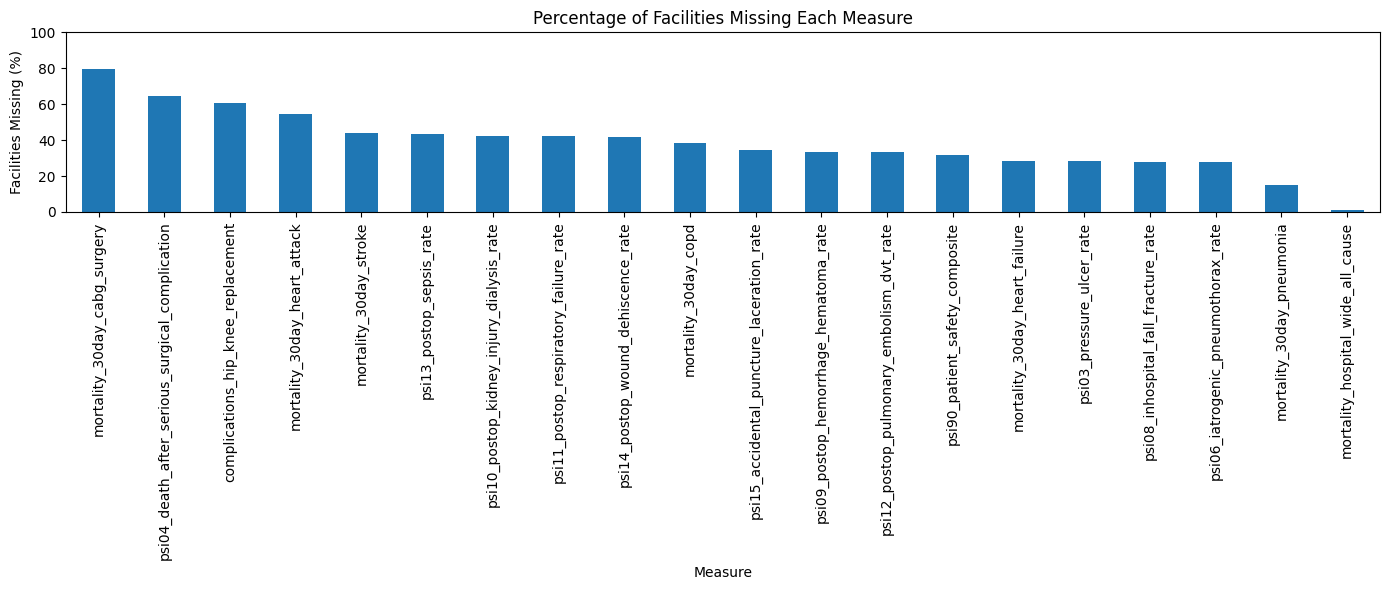

In [60]:
# Create summary table
missing_by_measure = pd.DataFrame({
    'Missing Facilities': scores.isna().sum(),
    'Total Facilities': len(scores),
    'Percentage Missing': scores.isna().mean() * 100
}).sort_values('Percentage Missing', ascending=False)

# Display table
display(missing_by_measure.round(2))

# Bar chart
ax = missing_by_measure['Percentage Missing'].plot(
    kind='bar',
    figsize=(14, 6)
)

ax.set_title('Percentage of Facilities Missing Each Measure')
ax.set_xlabel('Measure')
ax.set_ylabel('Facilities Missing (%)')
ax.tick_params(axis='x', rotation=90)
ax.set_ylim(0, 100)

plt.tight_layout()
plt.show()

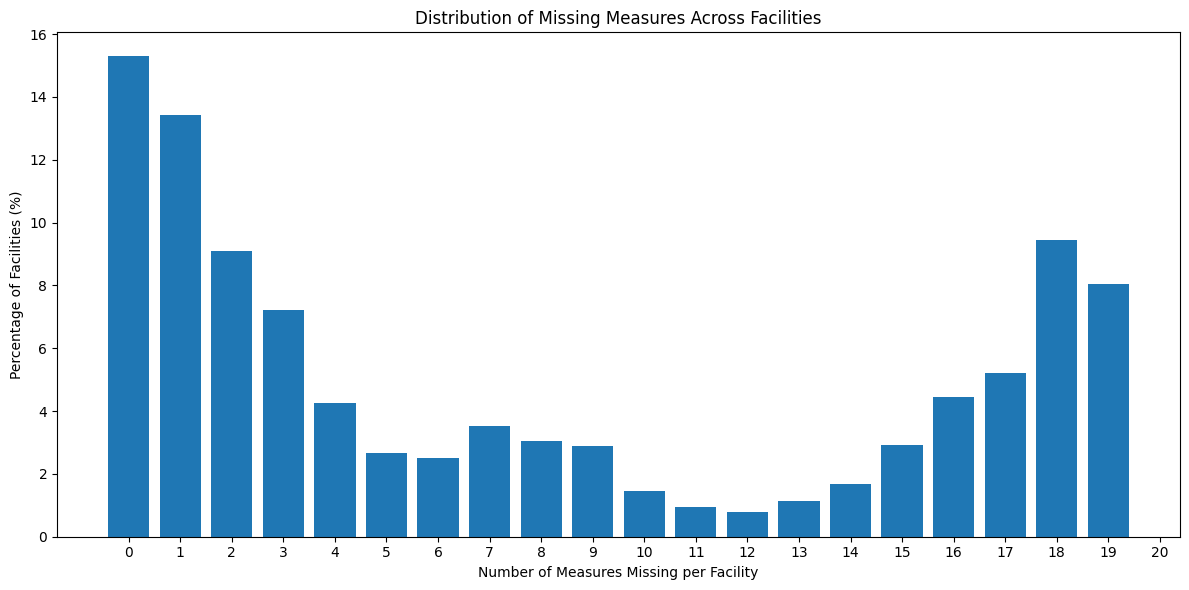

In [62]:
# Count facilities missing each possible number of measures
missing_distribution = (
    missing_count
    .value_counts()
    .reindex(range(len(measures) + 1), fill_value=0)
    .sort_index()
)

# Create summary table
distribution_table = pd.DataFrame({
    'Number of Measures Missing': missing_distribution.index,
    'Number of Facilities': missing_distribution.values,
    'Percentage of Facilities':
        missing_distribution.values / total_facilities * 100
})

# Display only counts that occur in the data
distribution_table = distribution_table[
    distribution_table['Number of Facilities'] > 0
].reset_index(drop=True)

# Bar chart
plt.figure(figsize=(12, 6))

plt.bar(
    distribution_table['Number of Measures Missing'],
    distribution_table['Percentage of Facilities']
)

plt.title('Distribution of Missing Measures Across Facilities')
plt.xlabel('Number of Measures Missing per Facility')
plt.ylabel('Percentage of Facilities (%)')
plt.xticks(range(len(measures) + 1))
plt.tight_layout()
plt.show()

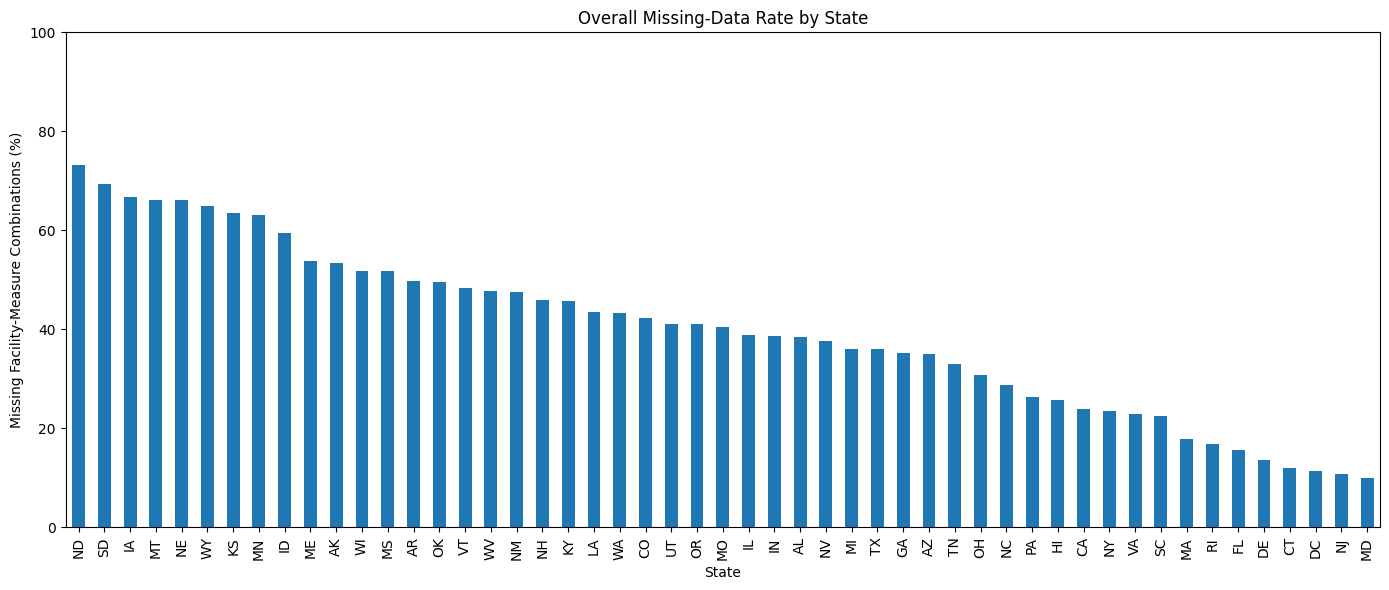

In [63]:
# Create one row per facility and one column per measure
scores = death_comp_hospital.pivot_table(
    index=['state', 'facility_id'],
    columns='measure_short_name',
    values='score',
    aggfunc='mean'
)

# Include all 24 measures
scores = scores.reindex(columns=measures)

# Calculate missing data for each facility
missing = scores.isna()

# Average percentage of missing scores across all facilities and measures
state_missing_pct = missing.groupby(level='state').mean().mean(axis=1) * 100

# Sort from highest to lowest
state_missing_pct = state_missing_pct.sort_values(ascending=False)

plt.figure(figsize=(14, 6))

state_missing_pct.plot(kind='bar')

plt.title('Overall Missing-Data Rate by State')
plt.xlabel('State')
plt.ylabel('Missing Facility-Measure Combinations (%)')
plt.xticks(rotation=90)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

# Summary table
state_missing_summary = pd.DataFrame({
    'Missing Data (%)': state_missing_pct,
    'Facilities': scores.groupby(level='state').size()
})

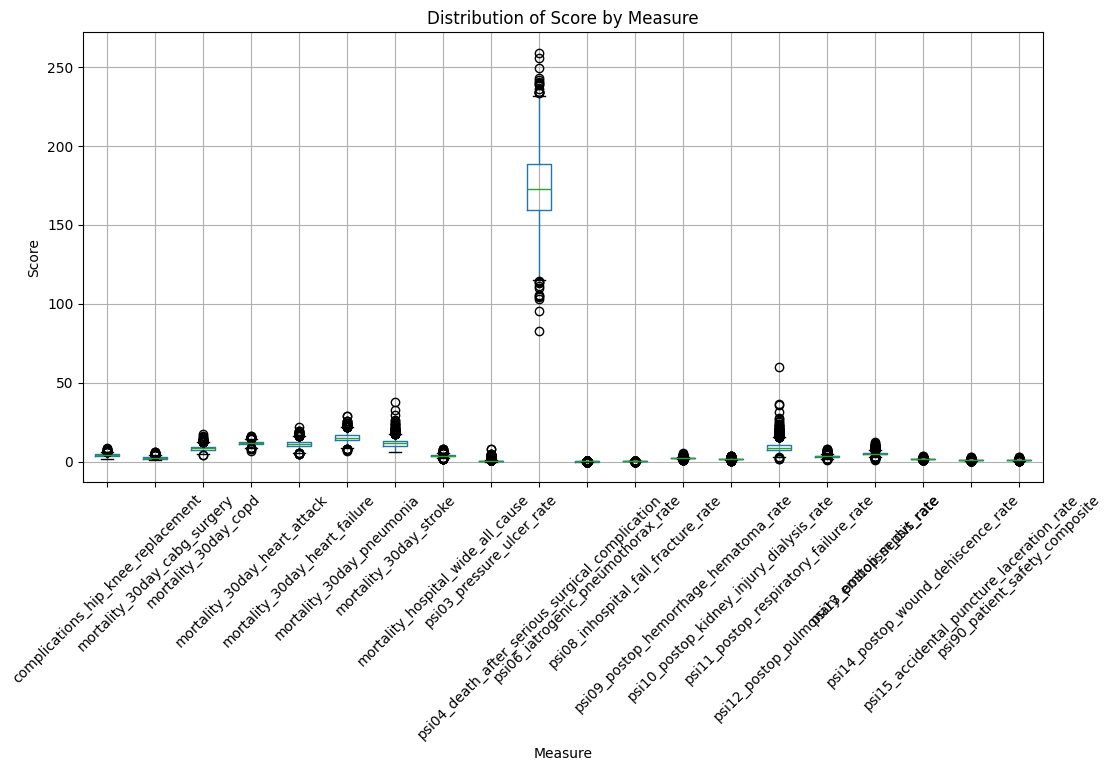

In [65]:
death_comp_hospital.boxplot(column='score', by='measure_short_name', figsize=(12, 6))

plt.title('Distribution of Score by Measure')
plt.suptitle('')
plt.xlabel('Measure')
plt.ylabel('Score')
plt.xticks(rotation=45)
plt.show()

### State Level

In [66]:
death_comp_state.head()

,geography_level,facility_type,source_file,state,measure_group,condition,measure_id,measure_short_name,measure_name,better_direction,ed_volume_tier,statistic,value,value_status,footnote_code,period_start,period_end
0,state,hospital,Timely_and_Effective_Care-State.csv,AK,Timely and Effective Care,Healthcare Personnel Vaccination,IMM_3,staff_flu_vaccination_pct,Healthcare workers given influenza vaccination...,higher,NaN,score,74.0,reported,NaN,2024-10-01,2025-03-31
1,state,hospital,Timely_and_Effective_Care-State.csv,AK,Timely and Effective Care,Emergency Department,OP_18a,ed_median_minutes_all_patients,Average (median) time all patients spent in th...,lower,NaN,score,143.0,reported,NaN,2024-10-01,2025-09-30
2,state,hospital,Timely_and_Effective_Care-State.csv,AK,Timely and Effective Care,Emergency Department,OP_18a,ed_median_minutes_all_patients,Average (median) time all patients spent in th...,lower,high,score,156.0,reported,NaN,2024-10-01,2025-09-30
3,state,hospital,Timely_and_Effective_Care-State.csv,AK,Timely and Effective Care,Emergency Department,OP_18a,ed_median_minutes_all_patients,Average (median) time all patients spent in th...,lower,low,score,136.0,reported,NaN,2024-10-01,2025-09-30
4,state,hospital,Timely_and_Effective_Care-State.csv,AK,Timely and Effective Care,Emergency Department,OP_18a,ed_median_minutes_all_patients,Average (median) time all patients spent in th...,lower,medium,score,152.0,reported,NaN,2024-10-01,2025-09-30


In [88]:
print(death_comp_state['state'].nunique())

# only include the 50 states and DC
states = [
    'AK', 'AL', 'AR', 'AZ', 'CA', 'CO', 'CT', 'DC', 'DE', 'FL',
    'GA', 'HI', 'IA', 'ID', 'IL', 'IN', 'KS', 'KY', 'LA', 'MA',
    'MD', 'ME', 'MI', 'MN', 'MO', 'MS', 'MT', 'NC', 'ND', 'NE',
    'NH', 'NJ', 'NM', 'NV', 'NY', 'OH', 'OK', 'OR', 'PA', 'RI',
    'SC', 'SD', 'TN', 'TX', 'UT', 'VA', 'VT', 'WA', 'WI', 'WV',
    'WY'
]

death_comp_state = death_comp_state[death_comp_state['state'].isin(states)].copy()
death_comp_state = death_comp_state[death_comp_state['ed_volume_tier'].isna()].copy()
print(death_comp_state['state'].nunique())

51
51


In [90]:
print(death_comp_state['value_status'].unique())
print(death_comp_state[death_comp_state['value_status']=='Not Available']['state'].unique())

['reported']
[]


In [91]:
# Convert scores to numeric
death_comp_state['value'] = pd.to_numeric(death_comp_state['value'], errors='coerce')

measures = death_comp_state["measure_short_name"].unique()

# Create one row per state and one column per measure
state_scores = death_comp_state.pivot_table(
    index='state',
    columns='measure_short_name',
    values='value',
    aggfunc='mean'
).reindex(columns=measures)

state_measure = death_comp_state.pivot_table(
    index='state',
    columns='measure_short_name',
    values='value',
    aggfunc='first'
)

# Count missing numerical values for each state
missing_by_state = state_measure.isna().sum(axis=1)

# Display states with missing values
print("States with missing numerical values:")
display(missing_by_state[missing_by_state > 0].sort_values(ascending=False))

# Confirm whether every state has every measure
if missing_by_state.sum() == 0:
    print("All states have numerical values for every measure.")
else:
    print(f"Total missing state-measure values: {missing_by_state.sum()}")

States with missing numerical values:


Series([], dtype: int64)

All states have numerical values for every measure.


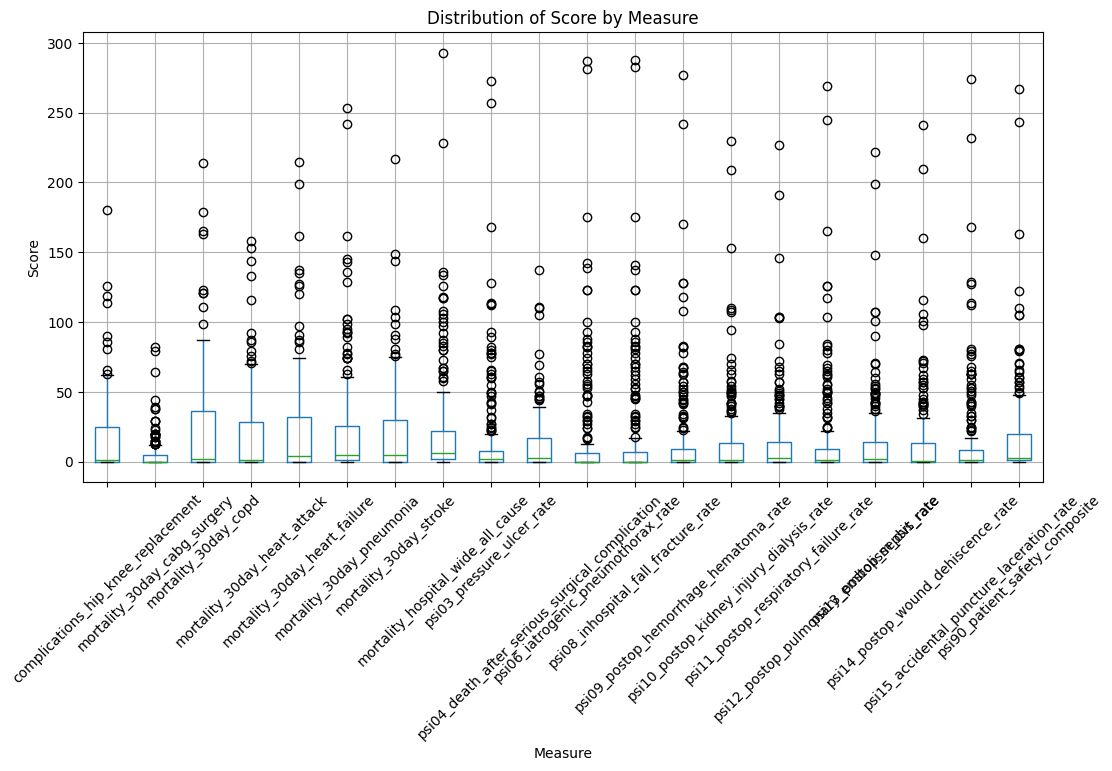

In [92]:
death_comp_state.boxplot(column='value', by='measure_short_name', figsize=(12, 6))

plt.title('Distribution of Score by Measure')
plt.suptitle('')
plt.xlabel('Measure')
plt.ylabel('Score')
plt.xticks(rotation=45)
plt.show()

/var/folders/0b/t60b2bh11pq2yknx9_cvds240000gn/T/ipykernel_10310/1598019363.py:28: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  ).apply(standardize_measure)


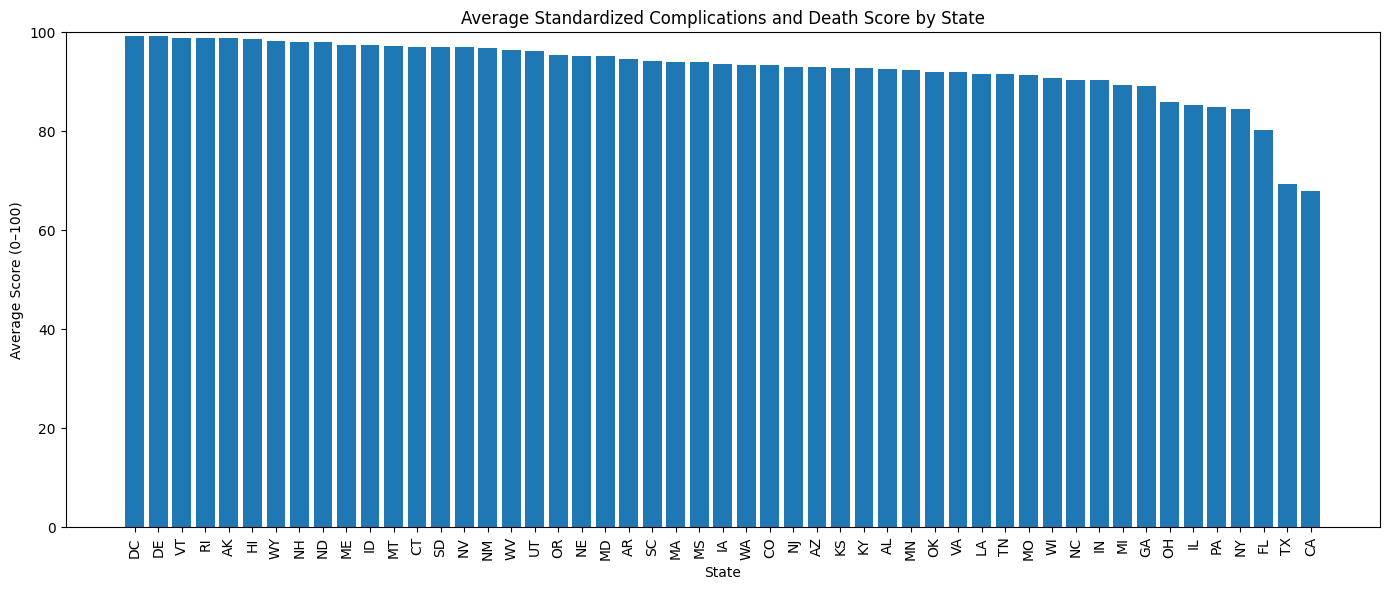

In [93]:
data = death_comp_state.copy()

# Ensure scores are numeric
data['value'] = pd.to_numeric(data['value'], errors='coerce')


# Standardize each measure to a 0–100 scale
def standardize_measure(group):
    min_val = group['value'].min()
    max_val = group['value'].max()

    if pd.isna(min_val) or pd.isna(max_val) or min_val == max_val:
        group['standardized_score'] = 50
    else:
        if group['better_direction'].iloc[0] == 'higher':
            group['standardized_score'] = (
                (group['value'] - min_val) / (max_val - min_val) * 100
            )
        else:
            group['standardized_score'] = (
                (max_val - group['value']) / (max_val - min_val) * 100
            )

    return group

data = data.groupby(
    'measure_short_name', group_keys=False
).apply(standardize_measure)

# Calculate average standardized score for each state
state_scores = (
    data.groupby('state')['standardized_score']
    .mean()
    .sort_values(ascending=False)
)

state_ranking = state_scores.reset_index()
state_ranking.columns = ['State', 'Average Score']

plt.figure(figsize=(14, 6))

plt.bar(state_ranking['State'], state_ranking['Average Score'])

plt.title('Average Standardized Complications and Death Score by State')
plt.xlabel('State')
plt.ylabel('Average Score (0–100)')
plt.xticks(rotation=90)
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

/var/folders/0b/t60b2bh11pq2yknx9_cvds240000gn/T/ipykernel_10310/4066392031.py:27: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  ).apply(standardize_measure)
/var/folders/0b/t60b2bh11pq2yknx9_cvds240000gn/T/ipykernel_10310/4066392031.py:40: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  ).apply(standardize_measure)


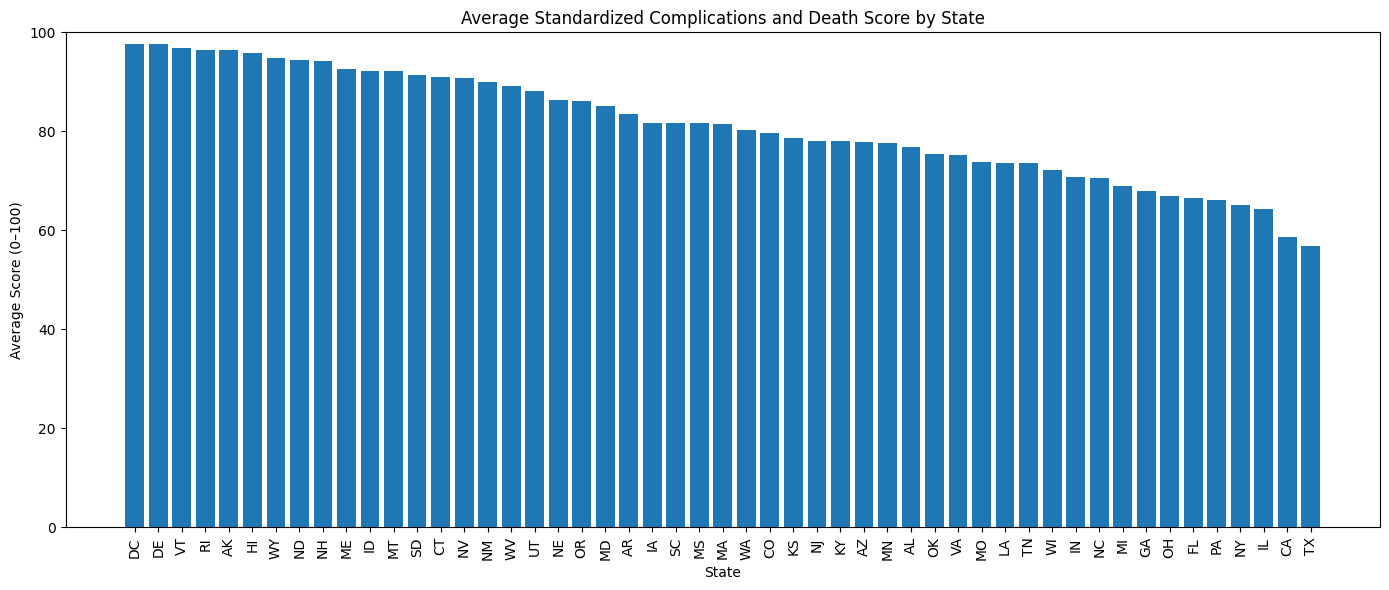

In [94]:
# 5th–95th percentile scaling to standardize

def standardize_measure(group):
    lower = group['value'].quantile(0.05)
    upper = group['value'].quantile(0.95)

    if pd.isna(lower) or pd.isna(upper) or lower == upper:
        group['standardized_score'] = 50
        return group

    # Cap values at the 5th and 95th percentiles
    capped = group['value'].clip(lower=lower, upper=upper)

    if group['better_direction'].iloc[0] == 'higher':
        group['standardized_score'] = (
            (capped - lower) / (upper - lower) * 100
        )
    else:
        group['standardized_score'] = (
            (upper - capped) / (upper - lower) * 100
        )

    return group

data = data.groupby(
    'measure_short_name', group_keys=False
).apply(standardize_measure)

state_ranking = (
    data.groupby('state')['standardized_score']
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

state_ranking.columns = ['State', 'Average Score']

data = data.groupby(
    'measure_short_name', group_keys=False
).apply(standardize_measure)

# Calculate average standardized score for each state
state_scores = (
    data.groupby('state')['standardized_score']
    .mean()
    .sort_values(ascending=False)
)

state_ranking = state_scores.reset_index()
state_ranking.columns = ['State', 'Average Score']

plt.figure(figsize=(14, 6))

plt.bar(state_ranking['State'], state_ranking['Average Score'])

plt.title('Average Standardized Complications and Death Score by State')
plt.xlabel('State')
plt.ylabel('Average Score (0–100)')
plt.xticks(rotation=90)
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

In [98]:
selected_states = ['DC', 'DE', 'CA', 'TX']

data = death_comp_state.copy()
data['value'] = pd.to_numeric(data['value'], errors='coerce')

# Summary statistics for each measure across all states
measure_summary = (
    data.groupby('measure_short_name')['value']
    .agg(
        Min='min',
        Mean='mean',
        Median='median',
        Max='max'
    )
    .reset_index()
)

# Scores for the two selected states
state_scores = data[
    data['state'].isin(selected_states)
].pivot_table(
    index='measure_short_name',
    columns='state',
    values='value',
    aggfunc='first'
).reset_index()

# Combine state scores and summary statistics
results = measure_summary.merge(
    state_scores,
    on='measure_short_name',
    how='left'
)

# Display all results
display(results.round(2))

,measure_short_name,Min,Mean,Median,Max,CA,DC,DE,TX
0,complications_hip_knee_replacement,0.0,15.02,1.5,180.0,2.0,0.0,0.0,0.0
1,mortality_30day_cabg_surgery,0.0,5.26,0.0,82.0,0.0,0.0,0.0,0.0
2,mortality_30day_copd,0.0,21.67,2.0,214.0,3.0,1.0,0.0,0.0
3,mortality_30day_heart_attack,0.0,18.37,1.0,158.0,6.0,0.0,0.0,0.0
4,mortality_30day_heart_failure,0.0,21.79,4.0,215.0,32.0,2.0,0.0,11.0
5,mortality_30day_pneumonia,0.0,22.10,4.5,253.0,33.0,0.0,0.0,12.0
6,mortality_30day_stroke,0.0,18.95,5.0,217.0,16.0,0.0,0.0,13.0
7,mortality_hospital_wide_all_cause,0.0,22.32,6.5,293.0,58.0,2.0,1.0,23.0
8,psi03_pressure_ulcer_rate,0.0,15.88,2.0,273.0,7.0,0.0,0.0,8.0
9,psi04_death_after_serious_surgical_complication,0.0,12.62,3.0,137.0,9.0,0.0,0.0,8.0


In [105]:
death_comp_hospital[death_comp_hospital['vs_national']=="Better"]

,geography_level,facility_type,source_file,facility_id,npi,shared_facility_id,facility_name,address,city,state,...,score,score_text,score_status,vs_national,cases,ci_lower,ci_upper,footnote_code,period_start,period_end
266,facility,hospital,Complications_and_Deaths-Hospital.csv,010033,NaN,False,UNIVERSITY OF ALABAMA HOSPITAL,619 SOUTH 19TH STREET,BIRMINGHAM,AL,...,12.20,NaN,reported,Better,308.0,9.60,15.10,NaN,2022-07-01,2025-06-30
519,facility,hospital,Complications_and_Deaths-Hospital.csv,010055,NaN,False,FLOWERS HOSPITAL,4370 WEST MAIN STREET,DOTHAN,AL,...,0.60,NaN,reported,Better,NaN,0.28,0.92,NaN,2022-07-01,2024-06-30
949,facility,hospital,Complications_and_Deaths-Hospital.csv,010103,NaN,False,PRINCETON BAPTIST MEDICAL CENTER,701 PRINCETON AVENUE SOUTHWEST,BIRMINGHAM,AL,...,105.27,NaN,reported,Better,60.0,59.10,151.45,NaN,2022-07-01,2024-06-30
1325,facility,hospital,Complications_and_Deaths-Hospital.csv,01014F,NaN,False,BIRMINGHAM VA MEDICAL CENTER,700 SOUTH 19TH STREET,BIRMINGHAM,AL,...,6.70,NaN,reported,Better,499.0,4.90,9.10,NaN,2022-07-01,2025-06-30
1801,facility,hospital,Complications_and_Deaths-Hospital.csv,020001,NaN,False,PROVIDENCE ALASKA MEDICAL CENTER,3200 PROVIDENCE DRIVE,ANCHORAGE,AK,...,3.20,NaN,reported,Better,2668.0,2.80,3.70,NaN,2024-07-01,2025-06-30
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
94826,facility,hospital,Complications_and_Deaths-Hospital.csv,670106,NaN,False,HCA HOUSTON HEALTHCARE PEARLAND,11100 SHADOW CREEK PARKWAY,PEARLAND,TX,...,10.90,NaN,reported,Better,62.0,8.10,14.40,NaN,2022-07-01,2025-06-30
94985,facility,hospital,Complications_and_Deaths-Hospital.csv,670122,NaN,False,HOUSTON METHODIST THE WOODLANDS HOSPITAL,17201 INTERSTATE 45 SOUTH,THE WOODLANDS,TX,...,7.60,NaN,reported,Better,727.0,5.30,10.70,NaN,2022-07-01,2025-06-30
94986,facility,hospital,Complications_and_Deaths-Hospital.csv,670122,NaN,False,HOUSTON METHODIST THE WOODLANDS HOSPITAL,17201 INTERSTATE 45 SOUTH,THE WOODLANDS,TX,...,9.30,NaN,reported,Better,786.0,6.70,12.80,NaN,2022-07-01,2025-06-30
94994,facility,hospital,Complications_and_Deaths-Hospital.csv,670122,NaN,False,HOUSTON METHODIST THE WOODLANDS HOSPITAL,17201 INTERSTATE 45 SOUTH,THE WOODLANDS,TX,...,2.96,NaN,reported,Better,684.0,0.00,8.69,NaN,2022-07-01,2024-06-30


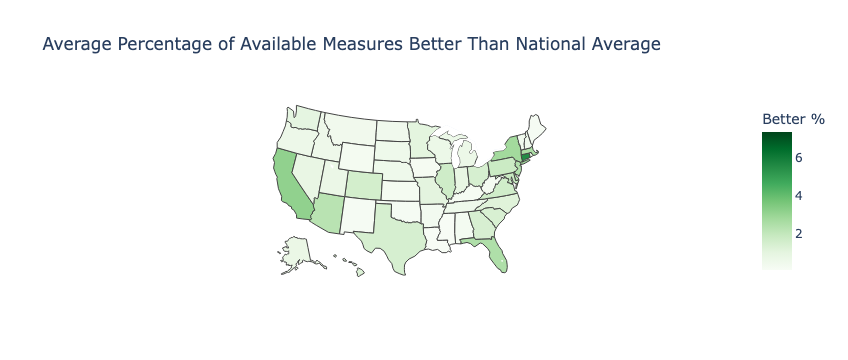

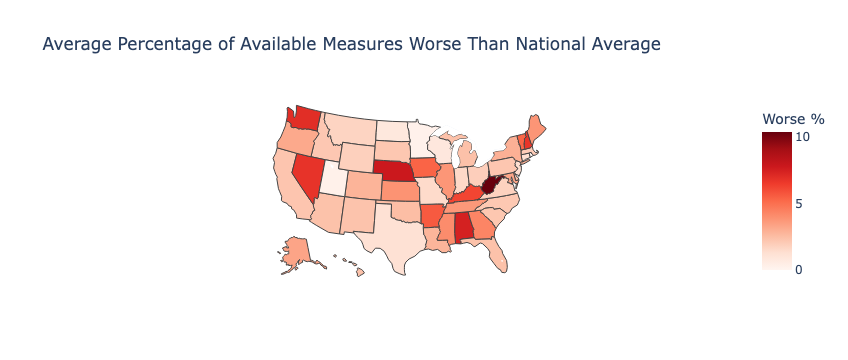

In [113]:
data = death_comp_hospital.copy()

# Keep only valid comparisons
data = data[
    data['vs_national'].isin(['Better', 'Worse', 'No Different'])
].copy()

# Count available measures and measures in each category for each hospital
hospital_performance = (
    data.groupby(['state', 'facility_id'])
    .agg(
        total_available=('vs_national', 'size'),
        better_count=('vs_national', lambda x: (x == 'Better').sum()),
        worse_count=('vs_national', lambda x: (x == 'Worse').sum())
    )
    .reset_index()
)

# Calculate percentages for each hospital
hospital_performance['Better %'] = (
    hospital_performance['better_count']
    / hospital_performance['total_available'] * 100
)

hospital_performance['Worse %'] = (
    hospital_performance['worse_count']
    / hospital_performance['total_available'] * 100
)

# Average hospital percentages within each state
state_performance = (
    hospital_performance.groupby('state')
    .agg(
        **{
            'Better %': ('Better %', 'mean'),
            'Worse %': ('Worse %', 'mean'),
            'Number of Hospitals': ('facility_id', 'nunique')
        }
    )
    .reset_index()
)

# Map: percentage of available measures classified as Better
fig_better = px.choropleth(
    state_performance,
    locations='state',
    locationmode='USA-states',
    color='Better %',
    scope='usa',
    color_continuous_scale='Greens',
    hover_data={
        'Better %': ':.2f',
        'Worse %': ':.2f',
        'Number of Hospitals': True
    },
    title='Average Percentage of Available Measures Better Than National Average'
)
fig_better.show()

# Map: percentage of available measures classified as Worse
fig_worse = px.choropleth(
    state_performance,
    locations='state',
    locationmode='USA-states',
    color='Worse %',
    scope='usa',
    color_continuous_scale='Reds',
    hover_data={
        'Better %': ':.2f',
        'Worse %': ':.2f',
        'Number of Hospitals': True
    },
    title='Average Percentage of Available Measures Worse Than National Average'
)
fig_worse.show()

In [133]:
asc_state = pd.read_csv("../Data_standard/state_asc.csv")
asc_state.head()

,geography_level,facility_type,source_file,state,measure_group,condition,measure_id,measure_short_name,measure_name,better_direction,ed_volume_tier,statistic,value,value_status,footnote_code,period_start,period_end
0,state,asc,ASC_State.csv,SC,ASC Quality Reporting,NaN,ASC_1,patient_burn,Number of patients who experience a burn prior...,lower,NaN,avg,0.000,reported,NaN,2024-01-01,2024-12-31
1,state,asc,ASC_State.csv,AZ,ASC Quality Reporting,NaN,ASC_1,patient_burn,Number of patients who experience a burn prior...,lower,NaN,avg,0.002,reported,NaN,2024-01-01,2024-12-31
2,state,asc,ASC_State.csv,LA,ASC Quality Reporting,NaN,ASC_1,patient_burn,Number of patients who experience a burn prior...,lower,NaN,avg,0.001,reported,NaN,2024-01-01,2024-12-31
3,state,asc,ASC_State.csv,MN,ASC Quality Reporting,NaN,ASC_1,patient_burn,Number of patients who experience a burn prior...,lower,NaN,avg,0.001,reported,NaN,2024-01-01,2024-12-31
4,state,asc,ASC_State.csv,NJ,ASC Quality Reporting,NaN,ASC_1,patient_burn,Number of patients who experience a burn prior...,lower,NaN,avg,0.001,reported,NaN,2024-01-01,2024-12-31


In [134]:
print(asc_state['state'].nunique())

# only include the 50 states and DC
states = [
    'AK', 'AL', 'AR', 'AZ', 'CA', 'CO', 'CT', 'DC', 'DE', 'FL',
    'GA', 'HI', 'IA', 'ID', 'IL', 'IN', 'KS', 'KY', 'LA', 'MA',
    'MD', 'ME', 'MI', 'MN', 'MO', 'MS', 'MT', 'NC', 'ND', 'NE',
    'NH', 'NJ', 'NM', 'NV', 'NY', 'OH', 'OK', 'OR', 'PA', 'RI',
    'SC', 'SD', 'TN', 'TX', 'UT', 'VA', 'VT', 'WA', 'WI', 'WV',
    'WY'
]

asc_state = asc_state[asc_state['state'].isin(states)].copy()
print(asc_state['state'].nunique())

54
51


In [136]:
asc_state['statistic'].unique()

array(['avg', 'median', 'n_better', 'n_same', 'n_worse', 'n_too_few'],
      dtype=object)

In [139]:
asc_state = asc_state[asc_state['statistic']=='avg']

In [140]:
asc_state['measure_id'].unique()

array(['ASC_1', 'ASC_2', 'ASC_3', 'ASC_4', 'ASC_9', 'ASC_11', 'ASC_13',
       'ASC_14'], dtype=object)

In [142]:
# Expected measures
expected_measures = ['ASC_1', 'ASC_2', 'ASC_3', 'ASC_4', 'ASC_9', 'ASC_11', 'ASC_13', 'ASC_14']

# Create a state-by-measure table
state_measure = asc_state.pivot_table(
    index='state',
    columns='measure_id',
    values='value',
    aggfunc='first'
).reindex(columns=expected_measures)

# Check for missing scores
missing_by_state = state_measure.isna().sum(axis=1)

# Display states with missing measures
print("States missing measures:")
display(
    missing_by_state[missing_by_state > 0]
    .sort_values(ascending=False)
)

# Identify the specific missing measures for each state
missing_details = {
    state: state_measure.columns[state_measure.loc[state].isna()].tolist()
    for state in state_measure.index
    if state_measure.loc[state].isna().any()
}

print("\nSpecific missing measures by state:")
display(pd.DataFrame(
    [(state, measure) for state, measures in missing_details.items()
     for measure in measures],
    columns=['State', 'Missing Measure']
))

# Overall completeness check
if missing_by_state.sum() == 0:
    print("All states have numerical scores for all 12 measures.")
else:
    print(f"Total missing state-measure scores: {missing_by_state.sum()}")

States missing measures:


state
VT    3
DC    2
AK    1
NH    1
WV    1
WI    1
VA    1
TN    1
SD    1
NM    1
ND    1
CT    1
MO    1
MN    1
ME    1
KY    1
KS    1
IA    1
HI    1
WY    1
dtype: int64


Specific missing measures by state:


,State,Missing Measure
0,AK,ASC_11
1,CT,ASC_11
2,DC,ASC_11
3,DC,ASC_14
4,HI,ASC_11
5,IA,ASC_11
6,KS,ASC_11
7,KY,ASC_11
8,ME,ASC_11
9,MN,ASC_11


Total missing state-measure scores: 23


In [143]:
# Ensure scores are numeric
asc_state['value'] = pd.to_numeric(
    asc_state['value'], errors='coerce'
)

# Count unique states in the dataset
total_states = asc_state['value'].nunique()

# Summarize score availability by measure
measure_availability = (
    asc_state.groupby('measure_id')
    .agg(
        States_With_Scores=('value', 'count'),
        Total_States=('state', 'nunique')
    )
    .reset_index()
)

# Measures with scores available for every state
complete_measures = measure_availability[
    (measure_availability['States_With_Scores'] == total_states)
    & (measure_availability['Total_States'] == total_states)
]

print("Measures with numerical scores available for every state:")
display(complete_measures)

print("\nAll measure availability:")
display(
    measure_availability.sort_values(
        'States_With_Scores', ascending=False
    )
)

Measures with numerical scores available for every state:


,measure_id,States_With_Scores,Total_States



All measure availability:


,measure_id,States_With_Scores,Total_States
2,ASC_13,51,51
4,ASC_2,51,51
6,ASC_4,51,51
7,ASC_9,51,51
0,ASC_1,50,51
3,ASC_14,50,51
5,ASC_3,50,51
1,ASC_11,31,51


In [145]:
selected_measures = ['ASC_13', 'ASC_2', 'ASC_4', 'ASC_9']

measure_names = (
    asc_state[
        asc_state['measure_id'].isin(selected_measures)
    ][['measure_id', 'measure_name']]
    .drop_duplicates()
    .sort_values('measure_id')
)

print(measure_names)

    measure_id                                       measure_name
864     ASC_13  Normothermia (body temperature of 96.8 F or hi...
108      ASC_2  Number of patients who experience a fall withi...
324      ASC_4  Percentage of ASC patients who are transferred...
432      ASC_9  Endoscopy/Polyp Surveillance: Appropriate Foll...
